# Notebook 01: Exploratory Data Analysis (EDA)
**Project:** Lightweight DNS-Based DGA Detection for Early Botnet Identification

Profiles the cleaned domain datasets, evaluates class balances, and visualizes lexical distributions.

In [1]:
import os, sys
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to sys.path
sys.path.insert(0, os.path.abspath('..'))
from src.preprocess import CLEAN_PARQUET_PATH

df = pd.read_parquet(os.path.join('..', CLEAN_PARQUET_PATH))
print(f'Total domains: {len(df):,}')
df.head(5)

Total domains: 200,000


,raw_domain,sld,subdomain,suffix,is_dga,family,first_seen,rank
0,pbdmrasildeafeninguvuc.com,pbdmrasildeafeninguvuc,,com,1,banjori,None,NaN
1,sciencenewslab.com,sciencenewslab,,com,0,benign,None,642956.0
2,qanfalitydevonianizuwb.com,qanfalitydevonianizuwb,,com,1,banjori,None,NaN
3,omochaoukoku.com,omochaoukoku,,com,0,benign,None,473454.0
4,surfeasy.mobi,surfeasy,,mobi,0,benign,None,34471.0


Class counts:
 is_dga
1    100000
0    100000
Name: count, dtype: int64


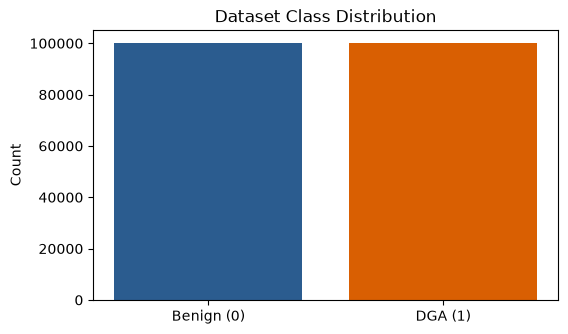

In [2]:
# Class Distribution
class_dist = df['is_dga'].value_counts()
print('Class counts:\n', class_dist)
plt.figure(figsize=(6, 3.5))
plt.bar(['Benign (0)', 'DGA (1)'], class_dist.values, color=['#2b5c8f', '#d95f02'])
plt.title('Dataset Class Distribution')
plt.ylabel('Count')
plt.show()

Top DGA Families:
 family
banjori                   55181
tinba                      8253
Post                       8197
ramnit                     5988
qakbot                     5019
necurs                     4015
murofet                    1784
pykspa                     1754
simda                      1733
ranbyus                    1724
shiotob/urlzone/bebloh     1569
dyre                        980
Cryptolocker                774
nymaim                      742
locky                       516
Name: count, dtype: int64


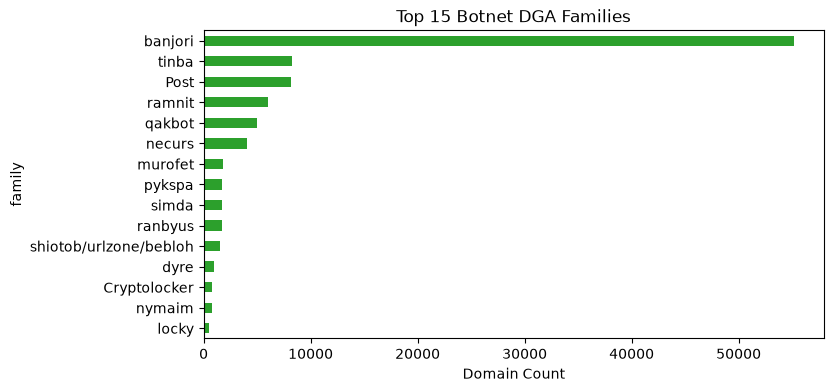

In [3]:
# Top DGA Malware Families
dga_families = df[df['is_dga'] == 1]['family'].value_counts().head(15)
print('Top DGA Families:\n', dga_families)
plt.figure(figsize=(8, 4))
dga_families.plot(kind='barh', color='#2ca02c')
plt.gca().invert_yaxis()
plt.title('Top 15 Botnet DGA Families')
plt.xlabel('Domain Count')
plt.show()

In [4]:
.venv\Scripts\python.exe -c "
import joblib
from src.features import extract_feature_vector

rf = joblib.load('models/detector_rf.joblib')
domains = ['google.com', 'microsoft.com', 'x8912kdmn901.biz', 'cxnvbm3819akls.ru']

print(f'{\"DOMAIN\":<25} | {\"PREDICTION\":<15} | {\"DGA PROBABILITY\"}')
print('-' * 60)
for d in domains:
    vec = extract_feature_vector(d, include_distribution=True).reshape(1, -1)
    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]
    label = 'MALICIOUS DGA' if pred == 1 else 'BENIGN'
    print(f'{d:<25} | {label:<15} | {prob*100:.2f}%')
"


SyntaxError: invalid syntax (3975832239.py, line 1)

In [1]:
print("JUPYTER IS WORKING")

JUPYTER IS WORKING


In [2]:
import joblib
print("JOBLIB IS WORKING")

JOBLIB IS WORKING


In [3]:
from src.features import extract_feature_vector
print("FEATURES WORKING")

ModuleNotFoundError: No module named 'src'

In [4]:
import sys
import os

sys.path.insert(0, os.path.abspath('..'))

print(os.path.abspath('..'))

C:\Users\HP\Downloads\dga_cn


In [5]:
from src.features import extract_feature_vector

print("FEATURES WORKING")

FEATURES WORKING


In [6]:
import joblib

rf = joblib.load('../models/detector_rf.joblib')

print("MODEL LOADED SUCCESSFULLY")

MODEL LOADED SUCCESSFULLY


In [7]:
domain = "google.com"

vec = extract_feature_vector(
    domain,
    include_distribution=True
).reshape(1, -1)

pred = rf.predict(vec)[0]
prob = rf.predict_proba(vec)[0][1]

label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

print("Domain:", domain)
print("Prediction:", label)
print("DGA Probability:", f"{prob * 100:.2f}%")

Domain: google.com
Prediction: BENIGN
DGA Probability: 4.02%


In [8]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------
google.com                | BENIGN          | 4.02%
microsoft.com             | BENIGN          | 7.44%
x8912kdmn901.biz          | BENIGN          | 20.37%
cxnvbm3819akls.ru         | BENIGN          | 27.33%


In [9]:
print("Model classes:", rf.classes_)
print("Number of features:", rf.n_features_in_)v

SyntaxError: invalid syntax (1694154153.py, line 2)

In [10]:
print("Model classes:", rf.classes_)
print("Number of features:", rf.n_features_in_)

AttributeError: 'RandomForestDetector' object has no attribute 'classes_'

In [11]:
print("predict:", rf.predict)
print("predict_proba:", rf.predict_proba)

predict: <bound method RandomForestDetector.predict of <src.detectors.RandomForestDetector object at 0x000001D14C05EE40>>
predict_proba: <bound method RandomForestDetector.predict_proba of <src.detectors.RandomForestDetector object at 0x000001D14C05EE40>>


In [12]:
for domain in [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    print(domain)
    print("Feature shape:", vec.shape)
    print("Prediction:", rf.predict(vec))
    print("Probability:", rf.predict_proba(vec))
    print("-" * 50)

google.com
Feature shape: (1, 37)
Prediction: [0]
Probability: [[0.95978457 0.04021543]]
--------------------------------------------------
microsoft.com
Feature shape: (1, 37)
Prediction: [0]
Probability: [[0.92557619 0.07442381]]
--------------------------------------------------
x8912kdmn901.biz
Feature shape: (1, 37)
Prediction: [0]
Probability: [[0.79628979 0.20371021]]
--------------------------------------------------
cxnvbm3819akls.ru
Feature shape: (1, 37)
Prediction: [0]
Probability: [[0.72668177 0.27331823]]
--------------------------------------------------


In [1]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------


NameError: name 'extract_feature_vector' is not defined

In [2]:
import sys
import os

sys.path.insert(0, os.path.abspath('..'))

from src.features import extract_feature_vector

In [3]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%')

SyntaxError: unterminated f-string literal (detected at line 22) (1565106917.py, line 22)

In [4]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------


NameError: name 'rf' is not defined

In [5]:
import joblib

rf = joblib.load('../models/detector_rf.joblib')

print("MODEL LOADED")


MODEL LOADED


In [6]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------
google.com                | BENIGN          | 2.39%
microsoft.com             | BENIGN          | 2.33%
x8912kdmn901.biz          | MALICIOUS DGA   | 69.92%
cxnvbm3819akls.ru         | MALICIOUS DGA   | 87.71%


In [1]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------


NameError: name 'extract_feature_vector' is not defined

In [2]:
import sys
import os

sys.path.insert(0, os.path.abspath('..'))

from src.features import extract_feature_vector

print("FEATURE EXTRACTOR LOADED")

FEATURE EXTRACTOR LOADED


In [3]:
import joblib

rf = joblib.load('../models/detector_rf.joblib')

print("MODEL LOADED SUCCESSFULLY")

MODEL LOADED SUCCESSFULLY


In [4]:
domains = [
    "google.com",
    "microsoft.com",
    "x8912kdmn901.biz",
    "cxnvbm3819akls.ru"
]

print(f'{"DOMAIN":<25} | {"PREDICTION":<15} | {"DGA PROBABILITY"}')
print("-" * 65)

for domain in domains:
    vec = extract_feature_vector(
        domain,
        include_distribution=True
    ).reshape(1, -1)

    pred = rf.predict(vec)[0]
    prob = rf.predict_proba(vec)[0][1]

    label = "MALICIOUS DGA" if pred == 1 else "BENIGN"

    print(f"{domain:<25} | {label:<15} | {prob * 100:.2f}%")

DOMAIN                    | PREDICTION      | DGA PROBABILITY
-----------------------------------------------------------------
google.com                | BENIGN          | 2.39%
microsoft.com             | BENIGN          | 2.33%
x8912kdmn901.biz          | MALICIOUS DGA   | 69.92%
cxnvbm3819akls.ru         | MALICIOUS DGA   | 87.71%
